# WP02 DrugBank keşfi ve ilaç kapsamı

**05.11.2026.** DrugBank bu tezde ilaç kimlikleri, ATC kapsamı, tuz–ana ilaç ilişkileri ve kaynakta bildirilen hedef bağlantılarının temelidir. SIDER yan etki etiketleri, PubChem ise kimyasal özellikler için ayrı kaynaklardır. Bir dosyada bulunan her ilaç bu tezin antibakteriyel kohortuna girmez.

Bu notebook **tam XML taramasından hesaplanmış küçük QC tablolarını** okur; her açılışta 1,9 GB dosyayı tekrar taramaz. Tam tarama `python scripts/wp02_drugbank.py` ile salt okunur yapılır. `iterparse`, sadece kökün doğrudan drug çocuklarını işler ve her biten kaydı remove/clear ile bırakır. İnceleme tabloları özellik veya eğitim tensörü değildir. Önceki WP00/WP01 çıktıları yeniden üretilmedi.

Kod hücrelerinin altındaki tablolar/grafikler gerçek yürütme çıktısıdır. Notebook yeniden çalıştırılabilir; internet gerekmez. Drive'dan yalnız izinli eski tablolar bellekte okunmuş, karşılaştırma için üyelik/kimlik özetleri saklanmıştır.

In [1]:
from pathlib import Path
import json,sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,FileLink
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'AGENTS.md').exists())
QA=ROOT/'reports/qa/WP02'; FIG=ROOT/'reports/figures/WP02';FIG.mkdir(parents=True,exist_ok=True)
records=json.loads((QA/'drug_registry.json').read_text(encoding='utf-8'))
summary=json.loads((QA/'summary.json').read_text(encoding='utf-8'))
manifest=json.loads((QA/'parse_manifest.json').read_text(encoding='utf-8'))
legacy=pd.read_csv(QA/'legacy_coverage.csv',keep_default_na=False)
mapping=pd.read_csv(QA/'old209_mapping.csv',keep_default_na=False)
registry=pd.DataFrame([{k:v for k,v in r.items() if k not in ['targets','salts']} for r in records])
j01=registry[registry.j01].copy()
conservative=registry[registry.j01_noncombination].copy()
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10})
def finish(name,title,ylabel='Kayıt sayısı'):
    ax=plt.gca();ax.set_title(title,loc='left',fontweight='bold');ax.set_ylabel(ylabel)
    plt.tight_layout();plt.savefig(FIG/(name+'.png'),dpi=160);plt.show()
display(pd.DataFrame([manifest]).drop(columns=['root_attributes']))
display(pd.DataFrame([manifest['root_attributes']]))

,bytes_read,source_path,size_bytes,elapsed_seconds,sampled_rss_peak_mib,os_peak_wset_mib,metadata_unchanged,source_mtime_ns,parse_complete,method
0,1898100846,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\...,1898100846,203.91692,145.289062,404.722656,True,1776457048961300200,True,stdlib iterparse; only depth=2 drug; remove+cl...


,{http://www.w3.org/2001/XMLSchema-instance}schemaLocation,version,exported-on
0,http://www.drugbank.ca http://www.drugbank.ca/...,5.1,2026-01-04


## 1 XML ve iç içe kayıtlar

`drugbank → drug` bir ana kayıttır. `drug → salts → salt` bir tuz varyantı, `drug → drug-interactions → drug` ise başka bir ilaca referanstır. İç içe tüm drug etiketlerini kayıt saymak veya salt ID'sini ana ID'nin üzerine yazmak yanlış sayım oluşturur. Ad, ATC ve kimlikler yalnız uygun **doğrudan çocuk yollarından** alınır.

Birincil kimlik `drug/drugbank-id[@primary="true"]`, ikincil kimlikler aynı düzeyde diğer drugbank-id alanlarıdır. İkincil kimlik yeni etkin madde değildir; eski ID'den güncel ana kayda bağlantıdır. Bir ID birden fazla ebeveyne giderse `ambiguous` tutulur.

,record_index,id,primary_count,name,type,secondary_ids,atc
0,1,DB00001,1,Lepirudin,biotech,"[BTD00024, BIOD00024]",[B01AE02]
1,2,DB00002,1,Cetuximab,biotech,"[BTD00071, BIOD00071]",[L01FE01]
2,3,DB00003,1,Dornase alfa,biotech,"[BTD00001, BIOD00001]",[R05CB13]
3,4,DB00004,1,Denileukin diftitox,biotech,"[BTD00084, BIOD00084]",[L01XX29]
4,5,DB00005,1,Etanercept,biotech,"[BTD00052, BIOD00052]",[L04AB01]


,ana kayıt,ikincil kimlik görülmesi,tuz ilişkisi,geçersiz ana kimlik,tekrarlanan ana kimlik
0,19830,5220,2960,0,0


,çok ebeveynli kimlik,eski üyelerde çözülemeyen,eski üyelerde belirsiz,ATC bulunmayan kaynak kaydı
0,0,0,0,16194


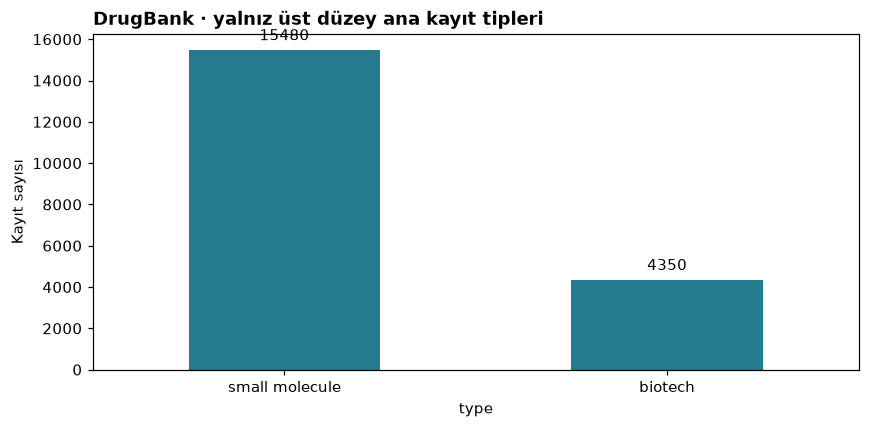

In [2]:
display(registry[['record_index','id','primary_count','name','type','secondary_ids','atc']].head(5))
display(pd.DataFrame([{'ana kayıt':summary['records'],'ikincil kimlik görülmesi':summary['secondary_id_occurrences'],
                       'tuz ilişkisi':summary['salt_occurrences'],'geçersiz ana kimlik':summary['invalid_primary_records'],
                       'tekrarlanan ana kimlik':len(summary['duplicate_primary_ids'])}]))
issues=json.loads((QA/'identity_issues.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'çok ebeveynli kimlik':issues['global_ambiguous_id_count'],
                       'eski üyelerde çözülemeyen':len(issues['legacy_members_unresolved']),
                       'eski üyelerde belirsiz':len(issues['legacy_members_ambiguous']),
                       'ATC bulunmayan kaynak kaydı':issues['all_records_missing_atc']}]))
ax=registry.type.value_counts().plot.bar(figsize=(8,4),rot=0,color='#237b8d');ax.bar_label(ax.containers[0],padding=4)
finish('01_record_types','DrugBank · yalnız üst düzey ana kayıt tipleri')

**Ne öğrendik?** Kayıt tipi dağılımı bütün DrugBank kapsamını gösterir. Salt sayıları bu çubuğa yeni ana ilaç olarak eklenmez. Bu kaynak kayıtları, benzersiz kimyasal temel etkin madde olduğu tamamen doğrulanmış moleküllerle bire bir eşit varsayılmaz.

## 2 ATC sınıflandırması ve J01

ATC hiyerarşisi ilacın kullanım sınıflarını kodlar. Örnek J01CA04: J ana grubu, J01 sistemik antibakteriyel sınıfı, sonraki harf/rakamlar daha dar alt grupları belirtir. Bir ilaç birden fazla ATC taşıyabilir. Bu tezde **kaynak-ATC ile doğrulanmış J01 adaylığı**, ana kayda doğrudan bağlı biçimi geçerli `J01[A-Z]{2}[0-9]{2}` kodunun bulunmasıdır. Ruhsat, tek bileşen, tuz/ingredient eşdeğerliği ve SIDER kapsamının tamamının doğrulandığı anlamına gelmez.

J02/D01 antifungal, J04 antimikobakteriyel, D06 topikal antibakteriyel gibi kodlar J01 olmadan ana kohorta eklenmez. ATC'si olmayan kayıt için isim son ekinden sınıf tahmini yapılmaz.

,id,name,atc,groups,secondary_ids
74,DB00080,Daptomycin,[J01XX09],"[approved, investigational]","[BTD00111, BIOD00111]"
185,DB00196,Fluconazole,"[D01AC15, J01RA07, J02AC01]","[approved, investigational]",[APRD00327]
188,DB00199,Erythromycin,"[D10AF02, D10AF52, J01FA01, S01AA17]","[approved, investigational, vet_approved]",[APRD00953]
196,DB00207,Azithromycin,"[J01FA10, J01RA07, J01RA16, S01AA26]","[approved, investigational]",[APRD00397]
207,DB00218,Moxifloxacin,"[J01MA14, S01AE07]","[approved, investigational]",[APRD00281]
218,DB00229,Cefotiam,[J01DC07],[approved],[APRD00855]
243,DB00254,Doxycycline,"[A01AB22, J01AA02, J01AA20]","[approved, investigational, vet_approved]",[APRD00597]
245,DB00256,Lymecycline,"[J01AA04, J01AA20]","[approved, withdrawn]","[APRD00565, EXPT01049]"
248,DB00259,Sulfanilamide,"[D06BA05, G01AE10, J01EB06]","[approved, withdrawn]",[APRD00438]
252,DB00263,Sulfisoxazole,"[G01AE10, J01EB05, S01AB02]","[approved, vet_approved]",[APRD00595]


,id,name,atc
185,DB00196,Fluconazole,"[D01AC15, J01RA07, J02AC01]"
188,DB00199,Erythromycin,"[D10AF02, D10AF52, J01FA01, S01AA17]"
196,DB00207,Azithromycin,"[J01FA10, J01RA07, J01RA16, S01AA26]"
207,DB00218,Moxifloxacin,"[J01MA14, S01AE07]"
243,DB00254,Doxycycline,"[A01AB22, J01AA02, J01AA20]"
245,DB00256,Lymecycline,"[J01AA04, J01AA20]"
248,DB00259,Sulfanilamide,"[D06BA05, G01AE10, J01EB06]"
252,DB00263,Sulfisoxazole,"[G01AE10, J01EB05, S01AB02]"
256,DB00267,Cefmenoxime,"[J01DD05, S01AA31, S02AA18]"
290,DB00301,Flucloxacillin,"[J01CF05, J01CR50]"


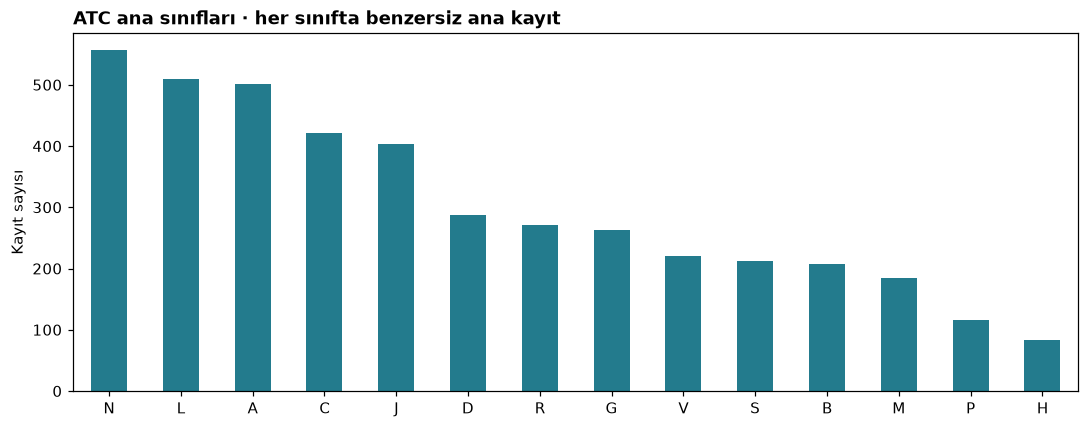

,durum,sayı
0,J01 adayı,237
1,J01 dışı / ATC yok,19593
2,J01 içinde birden fazla ATC,101


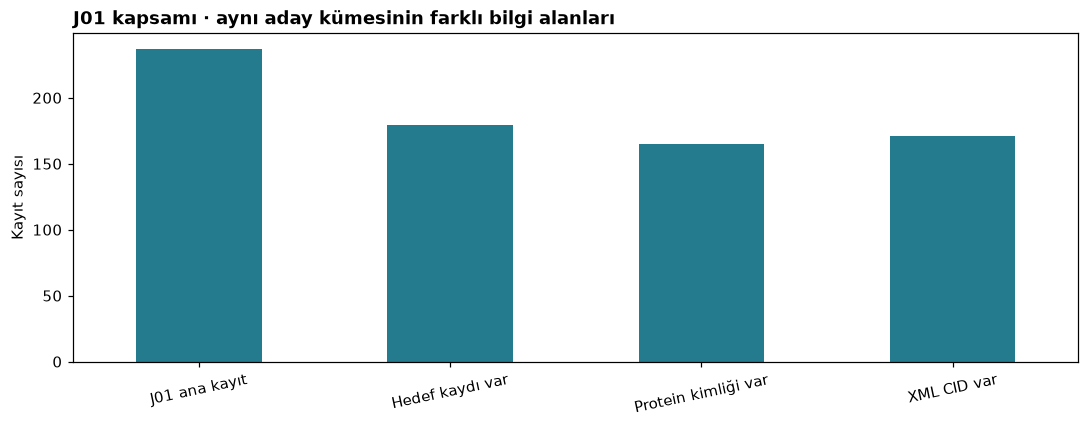

In [3]:
display(j01[['id','name','atc','groups','secondary_ids']].head(12))
display(j01[j01.atc.map(len)>1][['id','name','atc']].head(10))
from collections import Counter
atc_first=Counter(letter for codes in registry.atc for letter in {a[0] for a in codes})
pd.Series(atc_first).sort_values(ascending=False).plot.bar(figsize=(10,4),rot=0,color='#237b8d')
finish('02_atc_classes','ATC ana sınıfları · her sınıfta benzersiz ana kayıt')
display(pd.DataFrame({'durum':['J01 adayı','J01 dışı / ATC yok','J01 içinde birden fazla ATC'],
                     'sayı':[len(j01),len(registry)-len(j01),summary['multi_atc_j01']]}))
pd.Series({'J01 ana kayıt':len(j01),'Hedef kaydı var':summary['j01_with_target_entry'],
           'Protein kimliği var':summary['j01_with_protein'],'XML CID var':summary['j01_with_cid']}).plot.bar(figsize=(10,4),rot=12,color='#237b8d')
finish('03_j01_scope','J01 kapsamı · aynı aday kümesinin farklı bilgi alanları')

**Yorum:** ATC ana sınıf çubuklarının toplamı ilaç sayısını aşabilir; bir kayıt birkaç sınıfta olabilir. J01 kapsam grafiğinde hedef, protein ve CID alt kümeleri birbirini içermek zorunda değildir; çubuklar eğitim sayısı değildir. Eksik ATC, J01 dışı olmanın kanıtı olarak değil bu kaynakta J01 doğrulanamaması olarak yorumlanır.

In [4]:
display(registry[registry.j01_combination_only][['id','name','atc','groups']])
display(pd.DataFrame({'tanım':['Herhangi J01','J01R dışında J01','Yalnız J01R'],
                     'ana kayıt':[summary['j01'],summary['j01_noncombination'],summary['j01_combination_only']]}))
evidence=json.loads((QA/'schema_evidence.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'ID':e['id'],'ATC XML hiyerarşisi':e['atc_hierarchy']} for e in evidence['examples'] if e['id']=='DB00196']))
display(Markdown('**Önemli kapsam ayrımı:** Fluconazole, Nitazoxanide, Nystatin ve Secnidazole yalnız J01R kombinasyon koduyla geniş kümeye giriyor. XML hiyerarşisinde J01R “Combinations of antibacterials” olarak yazıyor. Bu dört kayıt ayrı inceleme listesinde; J01R dışında kod taşıyan **233** kayıt muhafazakâr aday kümesidir. Bu bir klinik kohort sonlandırma kararı değil, açıkça tanımlanmış analiz ayrımıdır.'))

,id,name,atc,groups
185,DB00196,Fluconazole,"[D01AC15, J01RA07, J02AC01]","[approved, investigational]"
493,DB00507,Nitazoxanide,"[J01RA17, P01AX11]","[approved, investigational, vet_approved]"
631,DB00646,Nystatin,"[A07AA02, D01AA01, G01AA01, G01AA51, J01RA19]","[approved, investigational, vet_approved]"
10922,DB12834,Secnidazole,"[J01RA07, P01AB07]","[approved, investigational]"


,tanım,ana kayıt
0,Herhangi J01,237
1,J01R dışında J01,233
2,Yalnız J01R,4


,ID,ATC XML hiyerarşisi
0,DB00196,"[<ns0:atc-code xmlns:ns0=""http://www.drugbank...."


**Önemli kapsam ayrımı:** Fluconazole, Nitazoxanide, Nystatin ve Secnidazole yalnız J01R kombinasyon koduyla geniş kümeye giriyor. XML hiyerarşisinde J01R “Combinations of antibacterials” olarak yazıyor. Bu dört kayıt ayrı inceleme listesinde; J01R dışında kod taşıyan **233** kayıt muhafazakâr aday kümesidir. Bu bir klinik kohort sonlandırma kararı değil, açıkça tanımlanmış analiz ayrımıdır.

## 3 DBSALT ile ana ilaç ilişkisi ve eski 209 kayıt

DBSALT bir tuz/varyant kaydının kimliğidir. XML'de belirli ana ilacın salts bloğu altında bulunması ebeveyn bağlantısının doğrudan kanıtıdır; tuzun farmakolojik ve kimyasal açıdan ana ilaçla tümüyle eşdeğer olduğunu tek başına kanıtlamaz. Ham tuz kimlikleri korunur, yalnız **tek ebeveynli** ilişkiler sayısal eşlemede kullanılır. Birincil/ikincil/tuz kimliklerinin çakıştığı durumlar otomatik birleştirilmez.

,id,old_name,old_atc,query_id,parents,status,parent_id,parent_name,parent_j01,parent_atc,id_kind
0,DB00080,Daptomycin,J01XX09,DB00080,"[""DB00080""]",resolved,DB00080,Daptomycin,True,"[""J01XX09""]",primary
1,DB00196,Fluconazole,J01RA07,DB00196,"[""DB00196""]",resolved,DB00196,Fluconazole,True,"[""D01AC15"", ""J01RA07"", ""J02AC01""]",primary
2,DBSALT002560,Moxifloxacin,J01MA14,DBSALT002560,"[""DB00218""]",resolved,DB00218,Moxifloxacin,True,"[""J01MA14"", ""S01AE07""]",DBSALT
3,DBSALT000796,Cefotiam,J01DC07,DBSALT000796,"[""DB00229""]",resolved,DB00229,Cefotiam,True,"[""J01DC07""]",DBSALT
4,DB00259,Sulfanilamide,J01EB06,DB00259,"[""DB00259""]",resolved,DB00259,Sulfanilamide,True,"[""D06BA05"", ""G01AE10"", ""J01EB06""]",primary
5,DBSALT001376,Sulfisoxazole,J01EB05,DBSALT001376,"[""DB00263""]",resolved,DB00263,Sulfisoxazole,True,"[""G01AE10"", ""J01EB05"", ""S01AB02""]",DBSALT
6,DBSALT000801,Cefmenoxime,J01DD05,DBSALT000801,"[""DB00267""]",resolved,DB00267,Cefmenoxime,True,"[""J01DD05"", ""S01AA31"", ""S02AA18""]",DBSALT
7,DBSALT000391,Cefmetazole,J01DC09,DBSALT000391,"[""DB00274""]",resolved,DB00274,Cefmetazole,True,"[""J01DC09""]",DBSALT
8,DBSALT000345,Flucloxacillin,J01CF05,DBSALT000345,"[""DB00301""]",resolved,DB00301,Flucloxacillin,True,"[""J01CF05"", ""J01CR50""]",DBSALT
9,DBSALT001460,Ertapenem,J01DH03,DBSALT001460,"[""DB00303""]",resolved,DB00303,Ertapenem,True,"[""J01DH03""]",DBSALT


,id_kind,status,satır
0,DBSALT,resolved,125
1,primary,resolved,84


,id,old_name,parent_id,parent_name,parent_j01,parent_atc
2,DBSALT002560,Moxifloxacin,DB00218,Moxifloxacin,True,"[""J01MA14"", ""S01AE07""]"
3,DBSALT000796,Cefotiam,DB00229,Cefotiam,True,"[""J01DC07""]"
5,DBSALT001376,Sulfisoxazole,DB00263,Sulfisoxazole,True,"[""G01AE10"", ""J01EB05"", ""S01AB02""]"
6,DBSALT000801,Cefmenoxime,DB00267,Cefmenoxime,True,"[""J01DD05"", ""S01AA31"", ""S02AA18""]"
7,DBSALT000391,Cefmetazole,DB00274,Cefmetazole,True,"[""J01DC09""]"
8,DBSALT000345,Flucloxacillin,DB00301,Flucloxacillin,True,"[""J01CF05"", ""J01CR50""]"
9,DBSALT001460,Ertapenem,DB00303,Ertapenem,True,"[""J01DH03""]"
10,DBSALT001067,Piperacillin,DB00319,Piperacillin,True,"[""J01CA12"", ""J01CR50""]"
11,DBSALT001061,Aztreonam,DB00355,Aztreonam,True,"[""J01DF01""]"
12,DBSALT001400,Sulfadiazine,DB00359,Sulfadiazine,True,"[""G01AE10"", ""J01EC02"", ""J01EE02"", ""J01EE06""]"


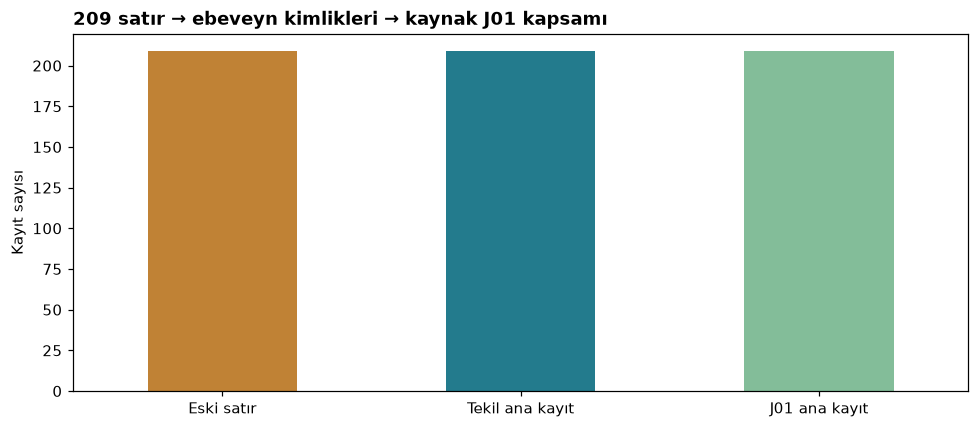

,id,old_name,old_atc,query_id,parents,status,parent_id,parent_name,parent_j01,parent_atc,id_kind


In [5]:
display(mapping.head(12))
display(mapping.groupby(['id_kind','status']).size().rename('satır').reset_index())
display(mapping[mapping.id_kind.eq('DBSALT')][['id','old_name','parent_id','parent_name','parent_j01','parent_atc']].head(12))
pd.Series({'Eski satır':len(mapping),'Tekil ana kayıt':summary['old209_unique_parents'],
           'J01 ana kayıt':summary['old209_unique_j01_parents']}).plot.bar(figsize=(9,4),rot=0,color=['#c08235','#237b8d','#83bd99'])
finish('04_salt_parent','209 satır → ebeveyn kimlikleri → kaynak J01 kapsamı')
display(mapping[(mapping.status!='resolved') | ~mapping.parent_j01.isin([True,'True'])].head(30))

**Yorum:** İlk çubuk satır, ikinci/üçüncü çubuk ana kayıt sayısıdır; paydaları farklıdır. Aynı ebeveyne giden farklı tuzlar yeni bağımsız ilaç olarak eklenmez. Eski ATC ile ebeveynin gerçek ATC'si uyuşmuyorsa kaynak ana kaydın kodu gösterilir; tarihsel etiket düzeltilmiş gibi sessizce değiştirilmez.

In [6]:
display(pd.DataFrame({'ölçüm':['Eski 209 → tekil ebeveyn','Ebeveynler içinde J01R dışı','237 kaynak adayında eski listede olmayan'],
                     'sayı':[summary['old209_unique_parents'],summary['old209_noncombination_parents'],summary['j01']-summary['old209_unique_j01_parents']]}))
display(j01[~j01.in_old209_parent][['id','name','atc']])
display(Markdown('**Verinin düzelttiği beklenti:** Bu özel 209 satır 209 farklı ana kayda gidiyor: 84 primary + 125 farklı ebeveyne giden DBSALT. Tuzları çözmek burada sayıyı azaltmadı. 125 eski tuz kimliğinin tamamı ebeveynin salts listesindeki son tuz ID’siyle eşleşiyor; bu, eski kodun aynı kayıtta ID üzerine yazma riskine uyumlu, fakat eksik 28 ilacın tek nedenini kanıtlamaz.'))

,ölçüm,sayı
0,Eski 209 → tekil ebeveyn,209
1,Ebeveynler içinde J01R dışı,205
2,237 kaynak adayında eski listede olmayan,28


,id,name,atc
188,DB00199,Erythromycin,"[D10AF02, D10AF52, J01FA01, S01AA17]"
196,DB00207,Azithromycin,"[J01FA10, J01RA07, J01RA16, S01AA26]"
243,DB00254,Doxycycline,"[A01AB22, J01AA02, J01AA20]"
245,DB00256,Lymecycline,"[J01AA04, J01AA20]"
433,DB00446,Chloramphenicol,"[D06AX02, D10AF03, G01AA05, J01BA01, S01AA01, ..."
440,DB00453,Clomocycline,[J01AA11]
466,DB00479,Amikacin,"[D06AX12, J01GB06, J01RA06, S01AA21]"
545,DB00560,Tigecycline,"[J01AA12, J01AA20]"
580,DB00595,Oxytetracycline,"[A01AB25, D06AA03, G01AA07, J01AA06, J01AA20, ..."
603,DB00618,Demeclocycline,"[D06AA01, J01AA01, J01AA20]"


**Verinin düzelttiği beklenti:** Bu özel 209 satır 209 farklı ana kayda gidiyor: 84 primary + 125 farklı ebeveyne giden DBSALT. Tuzları çözmek burada sayıyı azaltmadı. 125 eski tuz kimliğinin tamamı ebeveynin salts listesindeki son tuz ID’siyle eşleşiyor; bu, eski kodun aynı kayıtta ID üzerine yazma riskine uyumlu, fakat eksik 28 ilacın tek nedenini kanıtlamaz.

## 4 İlaç–hedef ilişkisi ve amino-acid-sequence

`targets/target` bir hedef kaydıdır; her hedef protein olmayabilir. `polypeptide/@id` ve UniProtKB dış kimliği aynı ise kimlik tutarlı olarak işaretlenir; farklıysa çatışma raporlanır. Polipeptit bulunmayan hedefe protein uydurulmaz. Gen adı protein anahtarı değildir; organizma bilgisi korunur.

WP00 bulgusu: polipeptit dizisi `amino-acid-sequence` alanında FASTA biçiminde olabilir; eski kodun `sequence` alanını araması aynı şey değildir. Burada yalnız alan varlığı/ham uzunluk incelenir. FASTA temizleme, AAC/DC ve protein özellik üretimi WP05'e aittir.

,drug_id,drug,target_id,target_name,organism,uniprot_id,id_status,aa_sequence_present,aa_raw_length,old_sequence_tag_present,gene_name,polypeptide_id_attribute,external_uniprot_ids,aa_header_prefix
0,DB00199,Erythromycin,BE0004800,23S ribosomal RNA,Enteric bacteria and other eubacteria,,no_polypeptide,False,0,False,NaN,NaN,NaN,NaN
1,DB00199,Erythromycin,BE0003521,Motilin receptor,Humans,O43193,consistent,True,452,False,MLNR,O43193,[O43193],>lcl|BSEQ0006793|Motilin receptor\nMGSPWNGSDGP...
2,DB00199,Erythromycin,BE0000090,Voltage-gated inwardly rectifying potassium ch...,Humans,Q12809,consistent,True,1253,False,KCNH2,Q12809,[Q12809],>lcl|BSEQ0000180|Voltage-gated inwardly rectif...
3,DB00207,Azithromycin,BE0004800,23S ribosomal RNA,Enteric bacteria and other eubacteria,,no_polypeptide,False,0,False,NaN,NaN,NaN,NaN
4,DB00207,Azithromycin,BE0001092,Protein-arginine deiminase type-4,Humans,Q9UM07,consistent,True,725,False,PADI4,Q9UM07,[Q9UM07],>lcl|BSEQ0016309|Protein-arginine deiminase ty...
5,DB00254,Doxycycline,BE0009998,30S ribosomal protein,,,no_polypeptide,False,0,False,NaN,NaN,NaN,NaN
6,DB00512,Vancomycin,BE0004826,D-Ala-D-Ala moiety of NAM/NAG peptide subunits...,Gram-positive Bacteria,,no_polypeptide,False,0,False,NaN,NaN,NaN,NaN
7,DB00601,Linezolid,BE0004800,23S ribosomal RNA,Enteric bacteria and other eubacteria,,no_polypeptide,False,0,False,NaN,NaN,NaN,NaN


,id,name,chemistry,adr,legacy_targets,j01,xml_target_entries,xml_proteins,xml_aa_proteins,chemistry_only_candidate
1,DB00199,Erythromycin,True,True,False,True,3,2,2,True
2,DB00207,Azithromycin,True,True,False,True,2,1,1,True
4,DB00254,Doxycycline,True,True,False,True,1,0,0,True
17,DB00512,Vancomycin,True,True,False,True,1,0,0,True
23,DB00601,Linezolid,True,True,False,True,1,0,0,True


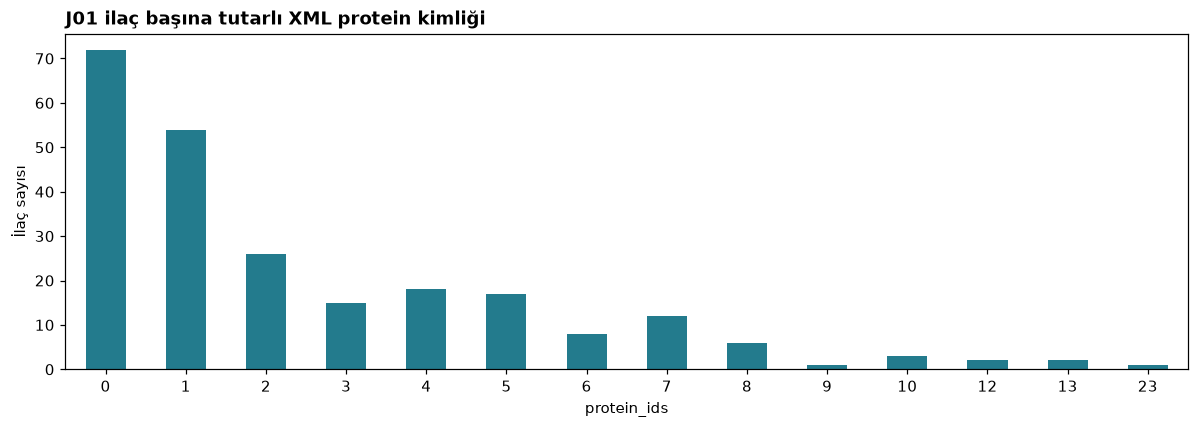

,alan,anlam
0,target kaydı,hedef ilişkisi var; protein olmayabilir
1,polipeptit / UniProt,protein kimliği mevcut; dış doğrulama değil
2,dizi alanı,FASTA/metadata; feature değil


In [7]:
priority=['Erythromycin','Azithromycin','Doxycycline','Vancomycin','Linezolid']
focus=[r for r in records if r['name'] in priority]
target_examples=[{'drug_id':r['id'],'drug':r['name'],**t} for r in focus for t in r['targets']]
display(pd.DataFrame(target_examples))
display(legacy[legacy.name.isin(priority)][['id','name','chemistry','adr','legacy_targets','j01','xml_target_entries','xml_proteins','xml_aa_proteins','chemistry_only_candidate']])
j01.protein_ids.map(len).value_counts().sort_index().plot.bar(figsize=(11,4),rot=0,color='#237b8d')
finish('05_proteins_per_drug','J01 ilaç başına tutarlı XML protein kimliği','İlaç sayısı')
display(pd.DataFrame({'alan':['target kaydı','polipeptit / UniProt','dizi alanı'],
                     'anlam':['hedef ilişkisi var; protein olmayabilir','protein kimliği mevcut; dış doğrulama değil','FASTA/metadata; feature değil']}))

**Yorum:** Eski hedef tablosunda bulunmamak, XML'de hedef bulunmamasıyla aynı değildir. XML'de de protein olmayan hedefler veya eksik kimlikler görülebilir. Histograma sıfır proteinli adaylar da dahildir. XML hedefinin varlığı, o ilacın yan etki etiketli veya GNN eğitimi için hazır olduğu anlamına gelmez.

## 5 PubChem CID ve SID

CID Compound kaydı, SID Substance kaydı kimliğidir; aynı sayı uzayı değildir. XML'deki kaynak etiketi saklanır. SID doğrudan CID sütununa taşınmaz. WP00'daki DrugBank–PubChem köprüsü ayrıca doğrulanır; bu notebook yeni API çağrısı yapmaz.

In [8]:
display(registry[registry.name.isin(priority+['Lepirudin'])][['id','name','pubchem_cid','pubchem_sid']])
display(legacy[legacy.name.isin(priority)][['id','name','cid','sid']])
display(pd.DataFrame([{'kaynak':'XML','CID olan J01':summary['j01_with_cid'],'J01 toplam':len(j01)}]))

,id,name,pubchem_cid,pubchem_sid
0,DB00001,Lepirudin,[],[46507011]
188,DB00199,Erythromycin,[12560],[46508487]
196,DB00207,Azithromycin,[447043],[46507743]
243,DB00254,Doxycycline,[54671203],[46506491]
497,DB00512,Vancomycin,[14969],[46505261]
586,DB00601,Linezolid,[441401],[46504452]


,id,name,cid,sid
1,DB00199,Erythromycin,12560,46508487
2,DB00207,Azithromycin,447043,46507743
4,DB00254,Doxycycline,54671203,46506491
17,DB00512,Vancomycin,14969,46505261
23,DB00601,Linezolid,441401,46504452


,kaynak,CID olan J01,J01 toplam
0,XML,171,237


**Yorum:** Tablo SID/CID ayrımını gerçek kayıtlarda gösterir. XML CID alanı boş olsa bile köprüde CID bulunabilir. Kimyasal yapı ve tuz eşdeğerliği doğrulanmadan “aynı molekül” sonucu çıkarılmaz.

## 6 Eski 38 ilaç ve yeni kaynak kapsamı

Eski 56 kimyalı, 53 ADR'li, 41 hedef bağlı ve 38 ortak ilaç üyelikleri izinli Drive tablolarından yeniden hesaplandı. XML J01 sınıfı bunlarla karşılaştırılır; yeni SIDER eşlemesi burada yapılmaz. Aşağıdaki tabloda eski ADR alanı yalnız **eski çıktıda kayıt var** demektir; eski tabloda olmayan ilaç için SIDER'da yok sonucu vermez.

,id,name,chemistry,adr,legacy_targets,old38,cid,sid,mapping_status,parent_id,xml_name,j01,atc,xml_target_entries,xml_proteins,xml_protein_ids,chemistry_only_candidate,xml_aa_proteins,j01_noncombination
0,DB00196,Fluconazole,True,True,True,True,3365,46505735,resolved,DB00196,Fluconazole,True,"[""D01AC15"", ""J01RA07"", ""J02AC01""]",1,1,"[""P10613""]",False,1,False
1,DB00199,Erythromycin,True,True,False,False,12560,46508487,resolved,DB00199,Erythromycin,True,"[""D10AF02"", ""D10AF52"", ""J01FA01"", ""S01AA17""]",3,2,"[""O43193"", ""Q12809""]",True,2,True
2,DB00207,Azithromycin,True,True,False,False,447043,46507743,resolved,DB00207,Azithromycin,True,"[""J01FA10"", ""J01RA07"", ""J01RA16"", ""S01AA26""]",2,1,"[""Q9UM07""]",True,1,True
3,DB00250,Dapsone,True,True,True,True,2955,46505300,resolved,DB00250,Dapsone,False,"[""D10AX05"", ""J04BA02"", ""J04BA50"", ""J04BA51""]",2,2,"[""P0C0X1"", ""P0C0X2""]",False,2,False
4,DB00254,Doxycycline,True,True,False,False,54671203,46506491,resolved,DB00254,Doxycycline,True,"[""A01AB22"", ""J01AA02"", ""J01AA20""]",1,0,[],True,0,True
5,DB00257,Clotrimazole,True,True,True,True,2812,46507927,resolved,DB00257,Clotrimazole,False,"[""A01AB18"", ""D01AC01"", ""G01AF02"", ""G01AF20""]",6,5,"[""O15554"", ""O75469"", ""P10613"", ""P25025"", ""Q8TD...",False,5,False
6,DB00259,Sulfanilamide,True,False,True,False,5333,46508306,resolved,DB00259,Sulfanilamide,True,"[""D06BA05"", ""G01AE10"", ""J01EB06""]",1,1,"[""P0AC13""]",False,1,True
7,DB00301,Flucloxacillin,True,True,True,True,21319,46508276,resolved,DB00301,Flucloxacillin,True,"[""J01CF05"", ""J01CR50""]",1,1,"[""Q8XJ01""]",False,1,True
8,DB00303,Ertapenem,True,True,True,True,150610,46506508,resolved,DB00303,Ertapenem,True,"[""J01DH03""]",8,8,"[""P02918"", ""P02919"", ""P08506"", ""P0AD65"", ""P0AD...",False,8,True
9,DB00319,Piperacillin,True,True,True,True,43672,46504757,resolved,DB00319,Piperacillin,True,"[""J01CA12"", ""J01CR50""]",4,4,"[""P0A3M6"", ""Q75Y35"", ""Q7CRA4"", ""Q8DNB6""]",False,4,True


,id,name,atc
3,DB00250,Dapsone,"[""D10AX05"", ""J04BA02"", ""J04BA50"", ""J04BA51""]"
5,DB00257,Clotrimazole,"[""A01AB18"", ""D01AC01"", ""G01AF02"", ""G01AF20""]"
21,DB00582,Voriconazole,"[""J02AC03""]"
25,DB00634,Sulfacetamide,"[""D10AF06"", ""G01AE10"", ""S01AB04""]"
33,DB00951,Isoniazid,"[""J04AC01"", ""J04AC51"", ""J04AM01"", ""J04AM02"", ""..."
38,DB01045,Rifampin,"[""J04AB02"", ""J04AM02"", ""J04AM05"", ""J04AM06"", ""..."
42,DB01110,Miconazole,"[""A01AB09"", ""A07AC01"", ""D01AC02"", ""D01AC52"", ""..."
43,DB01127,Econazole,"[""D01AC03"", ""G01AF05"", ""G01AF20"", ""G01AF55""]"
45,DB01153,Sertaconazole,"[""D01AC14"", ""G01AF19"", ""G01AF20""]"
51,DB01263,Posaconazole,"[""J02AC04""]"


,id,name,atc
7,DB00301,Flucloxacillin,"[""J01CF05"", ""J01CR50""]"
8,DB00303,Ertapenem,"[""J01DH03""]"
9,DB00319,Piperacillin,"[""J01CA12"", ""J01CR50""]"
10,DB00359,Sulfadiazine,"[""G01AE10"", ""J01EC02"", ""J01EE02"", ""J01EE06""]"
11,DB00415,Ampicillin,"[""J01CA01"", ""J01CA51"", ""J01CR50"", ""S01AA19""]"
12,DB00417,Phenoxymethylpenicillin,"[""J01CE02"", ""J01CE10"", ""J01CR50""]"
13,DB00440,Trimethoprim,"[""J01EA01"", ""J01EE01"", ""J01EE02"", ""J01EE03"", ""..."
16,DB00485,Dicloxacillin,"[""J01CF01"", ""J01CR50""]"
18,DB00537,Ciprofloxacin,"[""J01MA02"", ""J01RA10"", ""J01RA11"", ""J01RA12"", ""..."
20,DB00578,Carbenicillin,"[""J01CA03"", ""J01CR50""]"


,id,name,j01,xml_target_entries,xml_proteins,chemistry_only_candidate
1,DB00199,Erythromycin,True,3,2,True
2,DB00207,Azithromycin,True,2,1,True
4,DB00254,Doxycycline,True,1,0,True
14,DB00446,Chloramphenicol,True,3,3,True
15,DB00448,Lansoprazole,False,2,2,True
17,DB00512,Vancomycin,True,1,0,True
19,DB00560,Tigecycline,True,6,5,True
22,DB00595,Oxytetracycline,True,3,2,True
23,DB00601,Linezolid,True,1,0,True
26,DB00684,Tobramycin,True,4,0,True


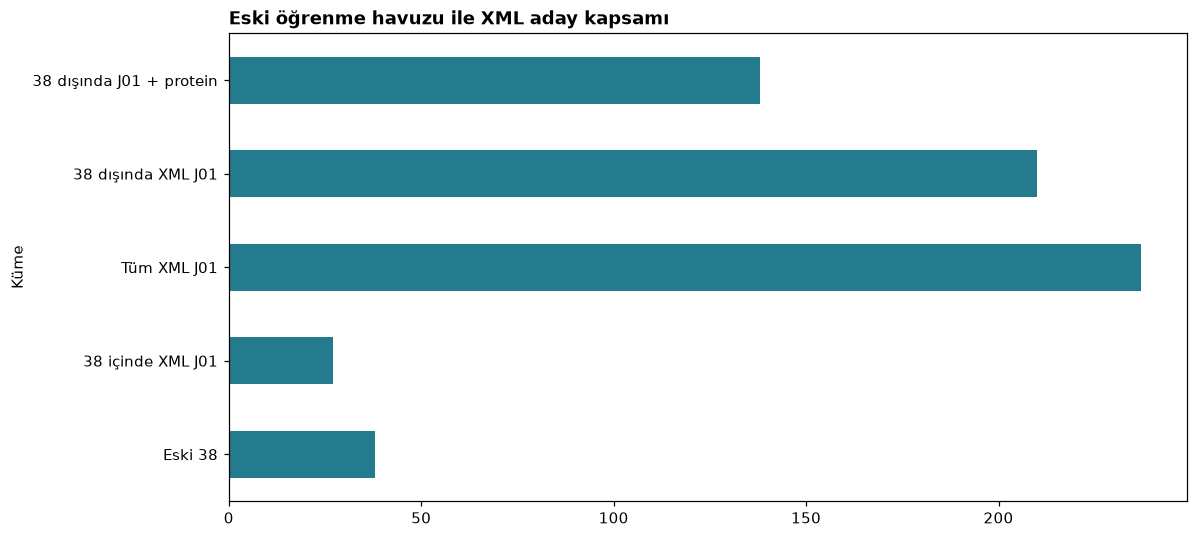

**Dikkat:** Bu çubuklar iç içe veya farklı kümelerdir; toplanmaz. Yeni adaylar ADR etiketli olarak sayılmamıştır.

In [9]:
display(legacy)
display(legacy[legacy.old38.eq(True) & legacy.j01.isin([False,'False'])][['id','name','atc']])
display(legacy[legacy.old38.eq(True) & legacy.j01_noncombination.eq(True)][['id','name','atc']])
display(legacy[legacy.chemistry_only_candidate.eq(True)][['id','name','j01','xml_target_entries','xml_proteins','chemistry_only_candidate']])
pd.Series({'Eski 38':int(legacy.old38.sum()),'38 içinde XML J01':summary['old38_j01'],
           'Tüm XML J01':summary['j01'],'38 dışında XML J01':summary['j01_outside_old38'],
           '38 dışında J01 + protein':summary['j01_outside_old38_with_protein']}).plot.barh(figsize=(11,5),color='#237b8d')
finish('06_old_new_scope','Eski öğrenme havuzu ile XML aday kapsamı','Küme')
display(Markdown('**Dikkat:** Bu çubuklar iç içe veya farklı kümelerdir; toplanmaz. Yeni adaylar ADR etiketli olarak sayılmamıştır.'))

In [10]:
display(pd.read_csv(QA/'cohort_funnel.csv'))
display(legacy[legacy.j01_noncombination.eq(True) & legacy.adr.eq(True) & (legacy.xml_proteins.astype(int)>0) & ~legacy.old38.eq(True)][['id','name','xml_proteins']])
bridge=json.loads((QA/'bridge_qc.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'köprü satırı':bridge['bridge_total'],'J01 kimliği köprüde eksik':bridge['missing_bridge'],
                      'J01 köprü CID var':bridge['with_bridge_cid'],'dolu CID uyuşmazlığı':len(bridge['conflicting_nonempty_cid'])}]))
display(Markdown('**Sonuç:** Eski 38 içinde 26 muhafazakâr J01 adayı, bir kombinasyon-only Fluconazole ve 11 J01 dışı kayıt var. Eski ADR kaydı taşıyan muhafazakâr adayların 34’ünde XML protein kimliği var; bu 26’ya göre sekiz potansiyel geri kazanım kaydıdır, eğitime hazır oldukları iddiası değildir.'))

,stage,count,meaning
0,Üst düzey ana kayıt,19830,Kaynak kaydı; ingredient eşdeğerliği değil
1,Doğrudan herhangi J01,237,Kombinasyon-only dahil
2,J01R dışında J01 kodu,233,Muhafazakâr analiz adayı
3,Bu adaylarda eski ADR kaydı,40,Yeni SIDER taraması değil
4,Önceki + XML protein kimliği,34,Yeni eğitim sayısı değil


,id,name,xml_proteins
1,DB00199,Erythromycin,2
2,DB00207,Azithromycin,1
14,DB00446,Chloramphenicol,3
19,DB00560,Tigecycline,5
22,DB00595,Oxytetracycline,2
32,DB00919,Spectinomycin,1
48,DB01172,Kanamycin,1
50,DB01211,Clarithromycin,4


,köprü satırı,J01 kimliği köprüde eksik,J01 köprü CID var,dolu CID uyuşmazlığı
0,19842,0,171,0


**Sonuç:** Eski 38 içinde 26 muhafazakâr J01 adayı, bir kombinasyon-only Fluconazole ve 11 J01 dışı kayıt var. Eski ADR kaydı taşıyan muhafazakâr adayların 34’ünde XML protein kimliği var; bu 26’ya göre sekiz potansiyel geri kazanım kaydıdır, eğitime hazır oldukları iddiası değildir.

## 7 Eksiklik ve belirsizlik

Boş veri, eşleme çatışması ve kaynakta ilişki görülmemesi farklı durumlardır. Aşağıdaki oranlar yalnız kaynak-J01 adaylarına aittir. “Eksik” alanı gerçek negatif olarak kodlanmaz.

,alan,eksik,payda,eksik_yüzde
0,XML Compound CID,66,237,27.85
1,Hedef kaydı,58,237,24.47
2,Tutarlı protein ID,72,237,30.38


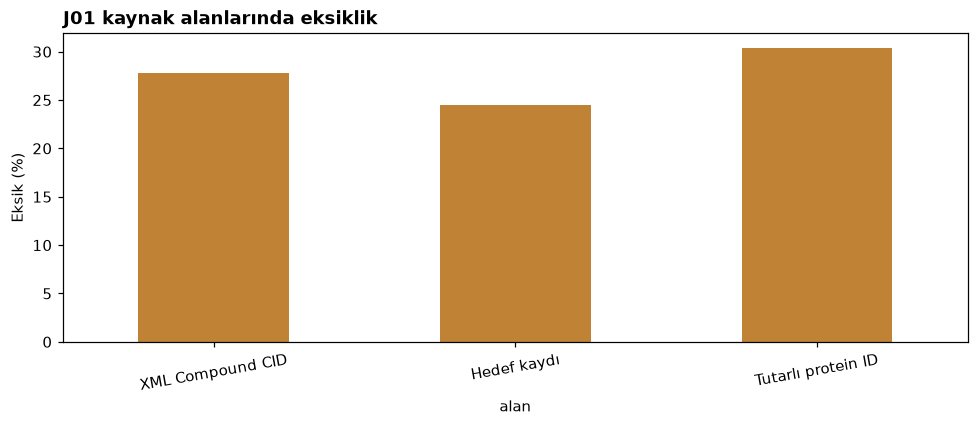

In [11]:
missing=pd.DataFrame([{'alan':'XML Compound CID','eksik':int(j01.pubchem_cid.map(len).eq(0).sum())},
                      {'alan':'Hedef kaydı','eksik':int(j01.target_entries.eq(0).sum())},
                      {'alan':'Tutarlı protein ID','eksik':int(j01.protein_ids.map(len).eq(0).sum())}])
missing['payda']=len(j01);missing['eksik_yüzde']=100*missing.eksik/missing.payda
display(missing.round(2))
missing.plot.bar(x='alan',y='eksik_yüzde',legend=False,figsize=(9,4),rot=10,color='#c08235')
finish('07_missingness','J01 kaynak alanlarında eksiklik','Eksik (%)')
missing.to_csv(QA/'missingness_j01.csv',index=False,encoding='utf-8-sig')

**Ne öğrendik?** Protein kaydı olmayan ama kimya ve ADR kaydı bulunan ilaçlar ileride moleküler baseline ile değerlendirilmeye adaydır. Bu, bilinmeyen protein ilişkisi eklemeyi gerektirmez. Yeni XML adaylarının gerçek SIDER PT/UMLS etiket kapsamı, CID/stereo eşlemesi ve tuz kararları WP03'te incelenecek; burada etiket/kohort genişleme garantisi verilmez.

## 8 Tuz bağlantılarını etkileşimli inceleme

Aşağıdaki HTML'de eski listedeki ilk sekiz çözümlü DBSALT ilişkisi ana kayda bağlanır. Tek ebeveyn kanıtı vardır; düğümler yeni ilaç sayımı değildir. Fareyle kimlikleri inceleyin. Plotly HTML kendi JavaScript paketini içerir, internet istemez.

In [12]:
import plotly.graph_objects as go
rows=mapping[mapping.id_kind.eq('DBSALT') & mapping.status.eq('resolved')].head(8)
parents=list(dict.fromkeys(rows.parent_id));salts=list(rows.id);labels=parents+salts
fig=go.Figure(go.Sankey(node=dict(label=labels,pad=25,thickness=18),
    link=dict(source=[parents.index(i) for i in rows.parent_id],target=[len(parents)+i for i in range(len(rows))],
              value=[1]*len(rows),customdata=list(rows.parent_name),hovertemplate='%{customdata}<extra></extra>')))
fig.update_layout(title_text='XML ebeveyn → DBSALT · sekiz gerçek bağlantı (bant = bir kayıt)',height=620)
path=FIG/'salt_parent_interactive.html';fig.write_html(path,include_plotlyjs=True)
display(rows[['parent_id','parent_name','id','old_name']]);display(FileLink(str(path)))

,parent_id,parent_name,id,old_name
2,DB00218,Moxifloxacin,DBSALT002560,Moxifloxacin
3,DB00229,Cefotiam,DBSALT000796,Cefotiam
5,DB00263,Sulfisoxazole,DBSALT001376,Sulfisoxazole
6,DB00267,Cefmenoxime,DBSALT000801,Cefmenoxime
7,DB00274,Cefmetazole,DBSALT000391,Cefmetazole
8,DB00301,Flucloxacillin,DBSALT000345,Flucloxacillin
9,DB00303,Ertapenem,DBSALT001460,Ertapenem
10,DB00319,Piperacillin,DBSALT001067,Piperacillin


C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\figures\WP02\salt_parent_interactive.html

## 9 Doğrulama ve sonraki kapı

Birincil kimlik, iç içe drug/ATC ayrımı, tuz ebeveyni, belirsiz eşleme, dizi etiketi ve duplicate kontrolleri `tests/test_wp02.py` içinde. Kaynak dosyanın boyut/mtime bilgisi tarama öncesi-sonrası kontrol edildi; tam hash alınmadı. Kaynakta bildirilen J01 adaylığı, benzersiz temel ingredient kimliğiyle aynı iddia değildir.

In [13]:
assert summary['invalid_primary_records']==0 and not summary['duplicate_primary_ids']
assert manifest['metadata_unchanged'] and manifest['parse_complete']
assert len(mapping)==209 and legacy.old38.sum()==38
assert len(j01)==summary['j01']
display(pd.DataFrame([summary]).drop(columns=['record_types','old209_mapping_status','duplicate_primary_ids']))
display(Markdown('**WP02 analizi tamamlandı.** WP03 için kullanıcı onayı beklenir.'))

,records,j01,j01_with_protein,j01_with_target_entry,j01_with_cid,multi_atc_all,multi_atc_j01,secondary_id_occurrences,salt_occurrences,unique_salt_ids,salt_ids_multiple_parents,old209_unique_parents,old209_unique_j01_parents,old38_j01,old38_not_j01,j01_outside_old38,j01_outside_old38_with_protein,invalid_primary_records,target_id_conflicts,j01_noncombination,j01_combination_only,old209_noncombination_parents,old38_noncombination,new_noncombination_with_protein
0,19830,237,165,179,171,944,101,5220,2960,2960,0,209,209,27,11,210,138,0,0,233,4,205,26,137


**WP02 analizi tamamlandı.** WP03 için kullanıcı onayı beklenir.